In [64]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D
import matplotlib as mpl
from matplotlib.patches import PathPatch, Rectangle
from matplotlib.path import Path as MplPath
from itertools import chain
from project_settings import PATH_WRK, BASE, METRIC, YEARS, RD_UNIT, DIMENSION

TECH = "TJ11"
# ============================================================
# WHICH MATRICES TO USE: value / volume, with or without technology
# ============================================================
# The matrices come from the runs of know_calc_loop. A "run" is identified by its output folder:
#   "SRDV (c,s)"          value  (RDV), no technology        "SRDQ (c,s)"          volume (RDQ), no technology
#   "SRDV (c,s,t)/TJ11"   value, technology TJ11             "SRDQ (c,s,t)/TJ11"   volume, technology TJ11
# run_id() builds this name from the three choices. By default the notebook uses the run chosen in
# project_settings.py (RD_UNIT, DIMENSION, TECH); to plot another one, set DEFAULT_RUN below, pass run=... to a
# plotting function, or give the run as the 4th element of a source in `sources` (to compare several runs).
def run_id(unit: str = "value", dimension: str = "(c,s)", tech: str = None) -> str:
    if unit not in ("value", "volume"):
        raise ValueError(f"unit must be 'value' or 'volume', got {unit!r}")
    if dimension not in ("(c,s)", "(c,s,t)"):
        raise ValueError(f"dimension must be '(c,s)' or '(c,s,t)', got {dimension!r}")
    root = ("SRDV" if unit == "value" else "SRDQ") + f" {dimension}"
    if dimension == "(c,s,t)":
        if not tech:
            raise ValueError("a technology is required with dimension '(c,s,t)', e.g. tech='TJ11'")
        return f"{root}/{tech}"
    return root


def run_label(run: str) -> str:
    """Readable label of a run, e.g. 'SRDV (c,s,t)/TJ11' -> 'value (c,s,t) TJ11'."""
    root, _, tech = run.partition("/")
    unit = "value" if root.startswith("SRDV") else "volume"
    return f"{unit} {root.split(' ', 1)[1]}" + (f" {tech}" if tech else "")


DEFAULT_RUN = run_id(RD_UNIT, DIMENSION, TECH if DIMENSION == "(c,s,t)" else None)   # run of project_settings
# DEFAULT_RUN = run_id("volume", "(c,s,t)", "TJ07")   # <- uncomment / edit to plot another run

# False: matrices at the native resolution of each base (files .csv)
# True : matrices aggregated on the common nomenclature (files _agg.csv, made by aggregate_to_common_mapping)
USE_AGG = False


def graphs_dir(runs) -> Path:
    """Folder where the figures are saved: runs/<run>/graphs_output/ for one run, runs/comparison/graphs_output/ otherwise."""
    runs = sorted(set(runs))
    folder = Path(PATH_WRK) / "runs" / (runs[0] if len(runs) == 1 else "comparison") / "graphs_output_loop"
    folder.mkdir(parents=True, exist_ok=True)
    return folder


def _savefig_safe(fig, path, **kwargs):
    """Comme fig.savefig(path, **kwargs), mais si le fichier est verrouille (ex. ouvert
    dans une visionneuse Windows), retente sous un nom alternatif au lieu de planter."""
    path = Path(path)
    try:
        fig.savefig(path, **kwargs)
        return path
    except OSError as exc:
        alt_path = path.with_stem(path.stem + "_new")
        print(f"Impossible d'ecrire {path.name} ({exc}) -> sauvegarde sous {alt_path.name}")
        fig.savefig(alt_path, **kwargs)
        return alt_path


In [65]:
# Pour chaque prefixe de metrique : (header, index_col) a passer a pd.read_csv
LAYOUTS = {
    "rd_dir_CI":     dict(header=[0, 1, 2], index_col=[0, 1, 2]),   # EXIOBASE / FIGARO / OECD_ICIO / GTAP
    "rd_embod_CI":   dict(header=[0, 1, 2], index_col=[0, 1, 2]),
    "rd_imp_CI":     dict(header=[0, 1, 2], index_col=[0, 1, 2]),
    "rd_dir_CFC":    dict(header=[0, 1, 2], index_col=[0, 1, 2]),   # CFC
    "rd_embod_CFC":  dict(header=[0, 1, 2], index_col=[0, 1, 2]),
    "rd_dir_cit":    dict(header=[0, 1],    index_col=[0, 1, 2]),   # Patents_Citation (index = Year, Region, Sector)
    "rd_dir_fdips":  dict(header=0,         index_col=[0, 1]),      # FDI (colonnes = Region seule)
}


def _match_layout(filename: str):
    """Trouve le prefixe de metrique (le plus long) qui matche le nom de fichier."""
    stem = filename.removesuffix(".csv")
    candidates = [prefix for prefix in LAYOUTS if stem.startswith(prefix + "_")]
    if not candidates:
        raise ValueError(f"Aucun layout connu pour {filename!r}")
    return max(candidates, key=len)


def load_matrix(path: Path) -> pd.DataFrame:
    """Charge un fichier de sortie de know_calc_loop (SRDV / SRDQ) en DataFrame bilateral (index = origine, colonnes = destination)."""
    layout = LAYOUTS[_match_layout(path.name)]
    df = pd.read_csv(path, sep=";", **layout)
    return df


In [66]:
_FOLDER_RE = re.compile(r"output_loop_(?P<base>.+)_(?P<year>\d{4})$")

RUN_ROOTS = ["SRDV (c,s)", "SRDQ (c,s)", "SRDV (c,s,t)", "SRDQ (c,s,t)"]
CATALOG_COLUMNS = ["run", "unit", "dimension", "tech", "base", "year", "metric", "aggregated", "path"]


def _run_dirs():
    """Every run folder found in the project: [(run, unit, dimension, tech, folder)]."""
    found = []
    for root in RUN_ROOTS:
        folder = Path(PATH_WRK) / root
        if not folder.is_dir():
            continue
        unit = "value" if root.startswith("SRDV") else "volume"
        dimension = root.split(" ", 1)[1]
        if dimension == "(c,s,t)":
            for tech_dir in sorted(d for d in folder.iterdir() if d.is_dir()):
                found.append((f"{root}/{tech_dir.name}", unit, dimension, tech_dir.name, tech_dir))
        else:
            found.append((root, unit, dimension, None, folder))
    return found


def discover_files(use_agg: bool = USE_AGG):
    """Catalog of all the matrices of all the runs: one row per (run, base, year, metric)."""
    rows = []
    for run, unit, dimension, tech, run_dir in _run_dirs():
        for base_dir in sorted(d for d in run_dir.iterdir() if d.is_dir()):
            for year_dir in sorted(base_dir.iterdir()):
                m = _FOLDER_RE.match(year_dir.name)
                if not m or not year_dir.is_dir():
                    continue
                year = int(m.group("year"))
                for csv_path in sorted(year_dir.glob("*.csv")):
                    aggregated = csv_path.stem.endswith("_agg")
                    if aggregated != use_agg:
                        continue
                    try:
                        metric = _match_layout(csv_path.name)
                    except ValueError:
                        continue
                    rows.append({
                        "run": run, "unit": unit, "dimension": dimension, "tech": tech,
                        "base": base_dir.name, "year": year, "metric": metric,
                        "aggregated": aggregated, "path": csv_path,
                    })
    return pd.DataFrame(rows, columns=CATALOG_COLUMNS)


catalog = discover_files()


def _get_path(base: str, metric: str, year: int, run: str = None, catalog: pd.DataFrame = catalog):
    """Path of the matrix of (run, base, metric, year), or None if it does not exist."""
    run = run or DEFAULT_RUN
    row = catalog[(catalog.run == run) & (catalog.base == base) & (catalog.year == year) & (catalog.metric == metric)]
    return None if row.empty else row.iloc[0]["path"]


def _no_file_message(base: str, metric: str, year: int, run: str = None) -> str:
    run = run or DEFAULT_RUN
    return (f"No file for {base}/{metric}/{year} in run {run!r}. Runs found: "
            f"{sorted(catalog.run.unique()) if len(catalog) else 'none'}")


print(f"default run: {DEFAULT_RUN} ({run_label(DEFAULT_RUN)}) | matrices: {'aggregated (_agg)' if USE_AGG else 'native nomenclature'}")
if len(catalog):
    print(catalog.groupby(["run", "base"]).year.agg(["min", "max", "count"]).rename(columns={"count": "n_files"}).to_string())
else:
    print("no matrix found: run know_calc_loop first")
catalog


default run: SRDV (c,s) (value (c,s)) | matrices: native nomenclature
                                     min   max  n_files
run               base                                 
SRDQ (c,s)        CFC               1995  2020       52
                  EXIOBASE          1995  2020       78
                  FDI               1995  2022       28
                  FIGARO            2010  2022       39
                  GTAP              1995  2020       78
                  OECD_ICIO         2016  2022       21
                  Patents_Citation  1995  2022       28
SRDV (c,s)        CFC               2010  2010        2
                  EXIOBASE          2010  2020        6
                  FIGARO            2010  2010        3
                  GTAP              1995  1995        3
                  OECD_ICIO         2016  2016        3
SRDV (c,s,t)/TJ01 EXIOBASE          2010  2010        3
                  FIGARO            2010  2010        3
                  GTAP            

,run,unit,dimension,tech,base,year,metric,aggregated,path
0,"SRDV (c,s)",value,"(c,s)",NaN,CFC,2010,rd_dir_CFC,False,"C:\Users\oscar\Desktop\ENTICE T3.4\SRDV (c,s)\..."
1,"SRDV (c,s)",value,"(c,s)",NaN,CFC,2010,rd_embod_CFC,False,"C:\Users\oscar\Desktop\ENTICE T3.4\SRDV (c,s)\..."
2,"SRDV (c,s)",value,"(c,s)",NaN,EXIOBASE,2010,rd_dir_CI,False,"C:\Users\oscar\Desktop\ENTICE T3.4\SRDV (c,s)\..."
3,"SRDV (c,s)",value,"(c,s)",NaN,EXIOBASE,2010,rd_embod_CI,False,"C:\Users\oscar\Desktop\ENTICE T3.4\SRDV (c,s)\..."
4,"SRDV (c,s)",value,"(c,s)",NaN,EXIOBASE,2010,rd_imp_CI,False,"C:\Users\oscar\Desktop\ENTICE T3.4\SRDV (c,s)\..."
...,...,...,...,...,...,...,...,...,...
390,"SRDV (c,s,t)/TJ11",value,"(c,s,t)",TJ11,GTAP,2010,rd_embod_CI,False,"C:\Users\oscar\Desktop\ENTICE T3.4\SRDV (c,s,t..."
391,"SRDV (c,s,t)/TJ11",value,"(c,s,t)",TJ11,GTAP,2010,rd_imp_CI,False,"C:\Users\oscar\Desktop\ENTICE T3.4\SRDV (c,s,t..."
392,"SRDV (c,s,t)/TJ11",value,"(c,s,t)",TJ11,OECD_ICIO,2016,rd_dir_CI,False,"C:\Users\oscar\Desktop\ENTICE T3.4\SRDV (c,s,t..."
393,"SRDV (c,s,t)/TJ11",value,"(c,s,t)",TJ11,OECD_ICIO,2016,rd_embod_CI,False,"C:\Users\oscar\Desktop\ENTICE T3.4\SRDV (c,s,t..."


In [67]:
def origin_totals(df: pd.DataFrame) -> pd.Series:
    s = df.sum(axis=1)
    if isinstance(df.index, pd.MultiIndex) and "Region" in df.index.names:
        s = s.groupby(level="Region").sum()
    return s.sort_values(ascending=False)


def destination_totals(df: pd.DataFrame) -> pd.Series:
    s = df.sum(axis=0)
    if isinstance(df.columns, pd.MultiIndex) and "Region" in df.columns.names:
        s = s.groupby(level="Region").sum()
    return s.sort_values(ascending=False)


In [68]:
REGION_TO_8R = {
    # Europe au sens large (UE + Suisse/Norvege/UK/Balkans), comme dans agg_FIGARO2_8R.xlsx
    "AT": "EU", "BE": "EU", "BG": "EU", "CY": "EU", "CZ": "EU", "DE": "EU", "DK": "EU",
    "EE": "EU", "ES": "EU", "FI": "EU", "FR": "EU", "GR": "EU", "HR": "EU", "HU": "EU",
    "IE": "EU", "IT": "EU", "LT": "EU", "LU": "EU", "LV": "EU", "MT": "EU", "NL": "EU",
    "PL": "EU", "PT": "EU", "RO": "EU", "SE": "EU", "SI": "EU", "SK": "EU",
    "CH": "EU", "NO": "EU", "UK": "EU", "IS": "EU",
    # Grandes zones individuelles
    "US": "US", "CA": "CA", "JP": "JP", "KR": "KR", "CN": "CN", "IN": "IN",
    # Reste du monde (tout le reste, y compris le code "RW" deja present dans les donnees)
    "AU": "RW", "BR": "RW", "MX": "RW", "RU": "RW", "RW": "RW", "TW": "RW",
    "SG": "RW", "IL": "RW", "CL": "RW", "ZA": "RW", "AR": "RW", "ID": "RW", "SA": "RW", "TR": "RW",
}
REGION_8R_ORDER = ["US", "CA", "EU", "JP", "KR", "CN", "IN", "RW"]


def _sector_level_name(names):
    """Le code secteur est sous 'Item' (familles EXIOBASE/FIGARO/OECD/GTAP/CFC) ou 'Sector' (Patents_Citation/FDI)."""
    if "Item" in names:
        return "Item"
    if "Sector" in names:
        return "Sector"
    return None


def _region_8r_index(idx):
    """Renvoie les labels 8R (Index simple) correspondant a un axe (MultiIndex ou Index simple)."""
    if isinstance(idx, pd.MultiIndex) and "Region" in idx.names:
        values = idx.get_level_values("Region")
    else:
        values = pd.Index(idx)
    return values.map(REGION_TO_8R)


def aggregate_to_8r(df: pd.DataFrame) -> pd.DataFrame:
    """Regroupe une matrice bilaterale (Region present sur les deux axes) en 8 macro-regions."""
    row_region = _region_8r_index(df.index)
    col_region = _region_8r_index(df.columns)

    grouped = df.groupby(row_region).sum()          # regroupe les lignes (origine)
    grouped = grouped.T.groupby(col_region).sum().T  # regroupe les colonnes (destination)
    return grouped.reindex(index=REGION_8R_ORDER, columns=REGION_8R_ORDER)


In [69]:
def list_sectors(base: str, metric: str, year: int, run: str = None, catalog: pd.DataFrame = catalog) -> list:
    """Liste les codes secteur ('Item' ou 'Sector') disponibles pour une base/metrique/annee.
    Utile car la nomenclature des secteurs varie selon la base (ex. EXIOBASE/CFC utilisent
    'C29_C30' combine, alors qu'un autre mapping pourrait avoir 'C29' seul)."""
    path = _get_path(base, metric, year, run, catalog)
    if path is None:
        raise ValueError(_no_file_message(base, metric, year, run))
    df = load_matrix(path)
    level = _sector_level_name(df.columns.names) if isinstance(df.columns, pd.MultiIndex) else None
    if level is None:
        return sorted(set(df.columns.astype(str)))
    return sorted(set(df.columns.get_level_values(level)))


_LEVEL_LABELS = {"country_sector": "pays x secteur", "country": "pays", "sector": "secteur"}

_METRIC_LABELS = {
    "rd_dir_CI": "consommation intermediaire directe",
    "rd_embod_CI": "contenu total incorpore (direct + indirect)",
    "rd_imp_CI": "R&D importee",
    "rd_dir_CFC": "consommation de capital fixe (directe)",
    "rd_embod_CFC": "consommation de capital fixe (incorporee)",
    "rd_dir_cit": "citations de brevets",
    "rd_dir_fdips": "investissements directs etrangers (FDI)",
}


def _build_palette(n: int) -> list:
    palettes = list(chain(plt.cm.tab20.colors, plt.cm.Set3.colors, plt.cm.Dark2.colors))
    if n > len(palettes):
        palettes *= int(np.ceil(n / len(palettes)))
    return palettes[:n]


def _axis_labels(index, level: str, region_map: dict = None) -> pd.Index:
    """Construit les labels d'un axe (lignes ou colonnes) selon le niveau de detail demande."""
    is_multi = isinstance(index, pd.MultiIndex) and "Region" in index.names
    region = index.get_level_values("Region") if is_multi else pd.Index(index)
    if region_map is not None:
        region = pd.Index(region).map(region_map)

    sector_name = _sector_level_name(index.names) if is_multi else None
    sector = index.get_level_values(sector_name) if sector_name else None

    if level == "country_sector":
        if sector is None:
            raise ValueError("Pas de niveau secteur disponible sur cet axe pour level='country_sector'.")
        return pd.Index(pd.Index(region).astype(str) + "-" + pd.Index(sector).astype(str))
    elif level == "country":
        return pd.Index(region).astype(str)
    elif level == "sector":
        if sector is None:
            raise ValueError("Pas de niveau secteur disponible sur cet axe pour level='sector'.")
        return pd.Index(sector).astype(str)
    else:
        raise ValueError("level doit etre 'country_sector', 'country' ou 'sector'")


def _filter_axis_mask(index, country: str = None, sector: str = None):
    """Masque booleen sur un axe : filtre par pays (MultiIndex avec 'Region', ou Index plat
    de codes pays) et/ou par secteur (necessite un niveau secteur). None = pas de filtre."""
    n = len(index)
    mask = np.ones(n, dtype=bool)

    if country is not None:
        if isinstance(index, pd.MultiIndex) and "Region" in index.names:
            mask &= (index.get_level_values("Region") == country)
        elif not isinstance(index, pd.MultiIndex):
            mask &= (pd.Index(index).astype(str) == country)
        else:
            raise ValueError("Cet axe n'a pas de niveau 'Region' pour filtrer par pays.")

    if sector is not None:
        sector_name = _sector_level_name(index.names) if isinstance(index, pd.MultiIndex) else None
        if sector_name is None:
            raise ValueError("Cet axe n'a pas de niveau secteur pour filtrer.")
        mask &= (index.get_level_values(sector_name) == sector)

    return mask


def _describe_axis(level: str, country: str = None, sector: str = None) -> str:
    label = _LEVEL_LABELS[level]
    restrictions = [v for v in (country, sector) if v is not None]
    if restrictions:
        label += " (" + ", ".join(restrictions) + " only)"
    return label


def plot_flow_sankey_full(base: str, metric: str, year: int,
                           origin_level: str = "country_sector", dest_level: str = "country_sector",
                           origin_country: str = None, origin_sector: str = None,
                           dest_country: str = None, dest_sector: str = None,
                           origin_region_map: dict = None, dest_region_map: dict = None,
                           top_n: int = 25,
                           figsize: tuple = (18, 12), node_margin: float = 0.005,
                           left_x: float = 0.15, right_x: float = 0.85,
                           title: str = None, save_name: str = None, run: str = None, catalog: pd.DataFrame = catalog):
    """"Curved ribbon" flow diagram, entierement parametrable.

    origin_level / dest_level : "country", "sector" ou "country_sector".
    origin_country / origin_sector / dest_country / dest_sector : filtre optionnel
        (None = garde tout) independant de chaque cote.
    run : matrices a utiliser (valeur / volume / technologie), cf. run_id() ; None = DEFAULT_RUN.
    top_n : garde les N plus gros FLUX individuels, APRES filtrage, tous cotes confondus
        (None = tous les flux positifs).

    Cas FDI : dans le fichier brut, les lignes sont (host, sector) = ou atterrit
    l'investissement, et les colonnes sont juste le pays source (investisseur, sans
    secteur). On transpose automatiquement pour retrouver la convention habituelle
    (origine = investisseur, destination = pays+secteur receveur) ; origin_level est
    alors force a 'country' puisque le secteur de l'investisseur n'existe pas.
    """
    run = run or DEFAULT_RUN   # value / volume / technology of the matrix: see run_id()
    path = _get_path(base, metric, year, run, catalog)
    if path is None:
        raise ValueError(_no_file_message(base, metric, year, run))
    df = load_matrix(path)

    if base == "FDI":
        df = df.T   # <-- lignes/colonnes brutes inversees pour FDI, cf. docstring
        if origin_level != "country":
            print(f"FDI: pas de secteur cote origine (investisseur) -> origin_level force a 'country' (etait {origin_level!r}).")
            origin_level = "country"
        if origin_sector is not None:
            print(f"FDI: pas de secteur cote origine -> origin_sector={origin_sector!r} ignore.")
            origin_sector = None

    row_mask = _filter_axis_mask(df.index, origin_country, origin_sector)
    col_mask = _filter_axis_mask(df.columns, dest_country, dest_sector)
    df = df.loc[row_mask, col_mask]
    if df.empty:
        raise ValueError(
            f"Aucune donnee apres filtrage (origin_country={origin_country!r}, "
            f"origin_sector={origin_sector!r}, dest_country={dest_country!r}, dest_sector={dest_sector!r})."
        )

    origin_labels = _axis_labels(df.index, origin_level, region_map=origin_region_map)
    dest_labels = _axis_labels(df.columns, dest_level, region_map=dest_region_map)

    flows = pd.DataFrame(df.values, index=origin_labels, columns=dest_labels)
    flows = flows.groupby(level=0).sum()
    flows = flows.T.groupby(level=0).sum().T

    long = flows.stack()
    long.index = long.index.set_names(["source", "target"])
    long = long[long > 0].sort_values(ascending=False)
    if top_n is not None:
        long = long.head(top_n)   # top-N flux, deja filtres
    if long.empty:
        raise ValueError("No positive flow to display with these parameters.")

    links = long.reset_index(name="value")
    total = links["value"].sum()
    links["share"] = links["value"] / total

    mpl.rcParams["font.family"] = "sans-serif"
    mpl.rcParams["font.sans-serif"] = ["Calibri", "DejaVu Sans"]
    mpl.rcParams["font.size"] = 11
    mpl.rcParams["axes.titlesize"] = 20
    mpl.rcParams["axes.titleweight"] = "bold"

    source_totals = links.groupby("source")["share"].sum().sort_values(ascending=False)
    target_totals = links.groupby("target")["share"].sum().sort_values(ascending=False)
    sources = source_totals.index.tolist()
    target_labels = target_totals.index.tolist()

    source_colors = dict(zip(sources, _build_palette(len(sources))))

    def compute_stacked_layout(totals, margin):
        n = len(totals)
        usable_height = 1 - margin * (n - 1)
        scale = usable_height / totals.sum()
        positions = {}
        y = 1
        for name, val in totals.items():
            h = val * scale
            y_low = y - h
            positions[name] = (y_low, y, (y + y_low) / 2, h)
            y = y_low - margin
        return positions, scale

    source_pos, source_scale = compute_stacked_layout(source_totals, node_margin)
    target_pos, target_scale = compute_stacked_layout(target_totals, node_margin)
    scale = min(source_scale, target_scale)
    source_offsets = {s: source_pos[s][0] for s in sources}
    target_offsets = {t: target_pos[t][0] for t in target_labels}

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.06)
    ax.axis("off")

    axis_title_style = dict(fontsize=18, fontweight="bold", color="black")
    ax.text(left_x, 1.03, "ORIGIN", ha="center", va="bottom", **axis_title_style)
    ax.text(right_x, 1.03, "DESTINATION", ha="center", va="bottom", **axis_title_style)
    ax.plot([left_x - 0.08, left_x + 0.08], [1.015, 1.015], lw=2, color="black")
    ax.plot([right_x - 0.08, right_x + 0.08], [1.015, 1.015], lw=2, color="black")

    label_fontsize = 9 if len(sources) > 25 else 10
    for s in sources:
        y_low, y_high, y_center, h = source_pos[s]
        ax.add_patch(Rectangle((left_x - 0.015, y_low), 0.02, h, color=source_colors[s], alpha=0.9))
        ax.text(left_x - 0.02, y_center, s, ha="right", va="center", fontsize=label_fontsize, color="black")

    target_fontsize = 9 if len(target_labels) > 25 else 12
    for t in target_labels:
        y_low, y_high, y_center, h = target_pos[t]
        ax.text(right_x + 0.01, y_center, t, ha="left", va="center",
                 fontsize=target_fontsize, fontweight="bold", color="black")

    def draw_flow(ax, x0, y0_low, y0_high, x1, y1_low, y1_high, color, alpha=0.55):
        verts = [
            (x0, y0_high), (0.5, y0_high), (0.5, y1_high), (x1, y1_high),
            (x1, y1_low), (0.5, y1_low), (0.5, y0_low), (x0, y0_low),
            (x0, y0_high),
        ]
        codes = [
            MplPath.MOVETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4,
            MplPath.LINETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4, MplPath.CLOSEPOLY,
        ]
        ax.add_patch(PathPatch(MplPath(verts, codes), facecolor=color, edgecolor="none", alpha=alpha))

    for _, r in links.iterrows():
        h = r["share"] * scale
        s, t = r["source"], r["target"]
        y0_low = source_offsets[s]; y0_high = y0_low + h; source_offsets[s] += h
        y1_low = target_offsets[t]; y1_high = y1_low + h; target_offsets[t] += h
        draw_flow(ax, left_x, y0_low, y0_high, right_x, y1_low, y1_high, source_colors[s])

    metric_label = _METRIC_LABELS.get(metric, metric)
    origin_desc = _describe_axis(origin_level, origin_country, origin_sector)
    dest_desc = _describe_axis(dest_level, dest_country, dest_sector)
    n_flows = len(links)
    flows_note = f"top {n_flows} flows" if top_n is not None else f"all positive flows ({n_flows})"

    auto_title = (
        f"R&D Flows - {base} {year} ({metric_label}) - {run_label(run)}\n"
        f"Origin: {origin_desc}  |  Destination: {dest_desc}  |  {flows_note}"
    )
    fig.suptitle(title or auto_title, fontsize=15, y=1.0)

    if save_name is None:
        def tag(level, country, sector):
            t = level
            if country: t += f"-{country}"
            if sector: t += f"-{sector}"
            return t
        save_name = (
            f"Sankey_{base}_{metric}_{year}_"
            f"{tag(origin_level, origin_country, origin_sector)}-to-"
            f"{tag(dest_level, dest_country, dest_sector)}_"
            f"{'top' + str(top_n) if top_n is not None else 'all'}"
        )
    _savefig_safe(fig, graphs_dir([run]) / f"{save_name}.png", dpi=300, bbox_inches="tight", facecolor="white")

    plt.show()
    return links

In [70]:
EXAMPLE_YEAR = YEARS[0] if YEARS else 2019   # year of the examples below

# Example: FDI flows towards C29_C30 (matrices of DEFAULT_RUN; add run=run_id("volume", "(c,s,t)", "TJ11") to use another run)
try:
    plot_flow_sankey_full(f"{BASE}", f"{METRIC}", EXAMPLE_YEAR,
                           dest_level="country_sector", dest_sector="C29_C30",
                           top_n=40)
except ValueError as exc:
    print(exc)


Aucune donnee apres filtrage (origin_country=None, origin_sector=None, dest_country=None, dest_sector='C29_C30').


In [71]:
def _select_column(df: pd.DataFrame, region: str, sector: str = None) -> pd.Series:
    """Selectionne (et fusionne si besoin) la ou les colonnes correspondant a une region
    (+ un secteur optionnel), quel que soit le nombre de niveaux de l'index des colonnes."""
    cols = df.columns
    if not isinstance(cols, pd.MultiIndex):
        if region not in cols:
            raise KeyError(region)
        return df[region]

    mask = (cols.get_level_values("Region") == region)
    if sector is not None:
        sector_name = _sector_level_name(cols.names)
        if sector_name is None:
            raise ValueError(f"Cet axe n'a pas de niveau secteur (colonnes: {cols.names}).")
        mask &= (cols.get_level_values(sector_name) == sector)

    if mask.sum() == 0:
        raise KeyError((region, sector))
    sub = df.loc[:, mask]
    return sub.iloc[:, 0] if sub.shape[1] == 1 else sub.sum(axis=1)


def _origin_shares(df: pd.DataFrame, target_region: str, target_sector: str,
                    origin_level: str = "country_sector", origin_region_map: dict = None,
                    top_n: int = 10, other_label: str = "Autres",
                    restrict_items: set = None) -> pd.Series:
    """Calcule les parts (fractions, somme=1) de chaque origine dans ce que recoit
    (target_region, target_sector). `restrict_items` : ne garder que ces codes secteur
    d'ORIGINE avant de calculer les parts (utile pour comparer plusieurs sources qui
    ne couvrent pas toutes les memes secteurs, ex. citations de brevets)."""
    s = _select_column(df, target_region, target_sector)
    idx = df.index

    if restrict_items is not None and isinstance(idx, pd.MultiIndex):
        sector_name = _sector_level_name(idx.names)
        if sector_name is not None:
            keep = np.asarray(idx.get_level_values(sector_name).isin(restrict_items))
            s = pd.Series(np.asarray(s.values)[keep], index=idx[keep])
            idx = idx[keep]

    origin_labels = _axis_labels(idx, origin_level, region_map=origin_region_map)
    grouped = pd.Series(s.values, index=origin_labels).groupby(level=0).sum()
    grouped = grouped[grouped > 0].sort_values(ascending=False)
    if grouped.empty:
        return pd.Series(dtype=float)

    share = grouped / grouped.sum()
    if top_n is not None and len(share) > top_n:
        top = share.iloc[:top_n].copy()
        rest = share.iloc[top_n:].sum()
        if rest > 0:
            top[other_label] = rest
        share = top
    return share


def _common_origin_sectors(dfs: list) -> set:
    """Intersection des codes secteur d'origine presents dans toutes les matrices `dfs`."""
    sets_list = []
    for df in dfs:
        if isinstance(df.index, pd.MultiIndex):
            name = _sector_level_name(df.index.names)
            if name is not None:
                sets_list.append(set(df.index.get_level_values(name)))
    return set.intersection(*sets_list) if sets_list else None


def _plot_stacked_percent_panel(ax, table: pd.DataFrame, other_label: str = "Autres",
                                 show_xlabel: bool = False, annotate_threshold: float = 0.08,
                                 xlabel_text: str = "Part de l'origine (%)",
                                 no_data_text: str = "(aucune donnee)"):
    """Un panel = un tableau (lignes = sources, colonnes = origines, valeurs = fractions 0-1)."""
    if table.empty:
        ax.axis("off")
        ax.set_title(no_data_text, fontsize=10, color="gray")
        return

    other_cols = [c for c in table.columns if c != other_label]
    order = table[other_cols].mean(axis=0).sort_values(ascending=False).index.tolist() if other_cols else []
    if other_label in table.columns:
        order = order + [other_label]
    table = table.reindex(columns=order, fill_value=0)

    palette = dict(zip(order, _build_palette(len(order))))
    if other_label in palette:
        palette[other_label] = (0.82, 0.82, 0.82)

    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#E3E3E3", linewidth=0.8)

    left = pd.Series(0.0, index=table.index)
    for col in order:
        vals = table[col]
        ax.barh(table.index, vals * 100, left=left * 100, height=0.65,
                color=palette[col], edgecolor="white", linewidth=0.6)
        for row_label, v in vals.items():
            if v >= annotate_threshold:
                ax.text(left[row_label] * 100 + v * 100 / 2, row_label, f"{v * 100:.0f}%",
                        ha="center", va="center", fontsize=8.5, color="white", fontweight="bold")
        left += vals

    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", length=0)
    if show_xlabel:
        ax.set_xlabel(xlabel_text)

    handles = [Line2D([0], [0], marker="s", linestyle="None", markersize=9, color=palette[c]) for c in order]
    ax.legend(handles, order, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False,
              ncol=1 if len(order) <= 8 else 2, fontsize=8.5)


def plot_origin_decomposition_panels(sources: list, region: str, item: str = None,
                                      origin_levels: tuple = ("country_sector", "country", "sector"),
                                      origin_region_map: dict = None,
                                      top_n: int = 8, other_label: str = "Autres",
                                      restrict_to_common_sectors: bool = True,
                                      labels: dict = None, level_labels: dict = None,
                                      xlabel_text: str = "Part de l'origine (%)",
                                      no_data_text: str = "(aucune donnee)",
                                      figsize: tuple = None,
                                      suptitle: str = None, save_name: str = None,
                                      catalog: pd.DataFrame = catalog):
    """`sources` : liste de (base, metric, year) ou (base, metric, year, run), ex.
        [("EXIOBASE","rd_dir_CI",2019), ("FIGARO","rd_dir_CI",2019), ("FDI","rd_dir_fdips",2019)]
    Le run (valeur / volume / technologie, cf. run_id()) est le 4e element ; sans lui, c'est DEFAULT_RUN.
    Comparer plusieurs runs = mettre des runs differents dans `sources`.
    Une ligne par source, un panel par niveau de `origin_levels`."""
    dfs, run_of = {}, {}
    for key in sources:
        base, metric, year = key[:3]
        run = key[3] if len(key) > 3 else DEFAULT_RUN
        path = _get_path(base, metric, year, run, catalog)
        if path is None:
            print(f"SKIP {key}: no file in the catalog (run {run!r})")
            continue
        df = load_matrix(path)
        if base == "FDI":
            df = df.T   # FDI : lignes/colonnes brutes inversees (source=colonnes, host+secteur=lignes)
        dfs[key] = df
        run_of[key] = run
    multi_run = len(set(run_of.values())) > 1

    restrict_items = _common_origin_sectors(list(dfs.values())) if restrict_to_common_sectors else None
    labels = labels or {}
    level_labels = level_labels or _LEVEL_LABELS

    def row_label(key):
        base, metric, year = key[:3]
        default = f"{base} ({_METRIC_LABELS.get(metric, metric)})"
        if multi_run:
            default += f" [{run_label(run_of[key])}]"
        return labels.get(key, default)

    n_panels = len(origin_levels)
    if figsize is None:
        figsize = (11, 3.0 * n_panels)
    fig, axes = plt.subplots(n_panels, 1, figsize=figsize)
    axes = np.atleast_1d(axes)

    for ax, level in zip(axes, origin_levels):
        use_restrict = restrict_items if level != "country" else None
        rows = {}
        for key, df in dfs.items():
            try:
                shares = _origin_shares(df, region, item, origin_level=level,
                                         origin_region_map=origin_region_map,
                                         top_n=top_n, other_label=other_label,
                                         restrict_items=use_restrict)
            except Exception as exc:
                print(f"SKIP {key} ({level}): {exc}")
                continue
            if shares.empty:
                print(f"SKIP {key} ({level}): aucun flux positif")
                continue
            rows[row_label(key)] = shares
        table = pd.DataFrame(rows).T.fillna(0) if rows else pd.DataFrame()
        _plot_stacked_percent_panel(ax, table, other_label=other_label,
                                     show_xlabel=(level == origin_levels[-1]),
                                     xlabel_text=xlabel_text, no_data_text=no_data_text)
        ax.set_title(level_labels[level].capitalize(), loc="left", fontsize=12)

    dest_label = f"{region}-{item}" if item else region
    run_note = "" if not run_of else (" (" + (run_label(next(iter(run_of.values()))) if not multi_run else "several runs") + ")")
    fig.suptitle(suptitle or f"Origin decomposition — {dest_label}{run_note}", x=0.02, y=1.0,
                 ha="left", fontsize=16, fontweight="bold")
    fig.tight_layout()

    if save_name is None:
        save_name = f"Origin_decomposition_{dest_label}"
    _savefig_safe(fig, graphs_dir(run_of.values() if run_of else [DEFAULT_RUN]) / f"{save_name}.png", dpi=250,
                  bbox_inches="tight", facecolor="white")
    plt.show()




SKIP ('FIGARO', 'rd_dir_CI', 2020): no file in the catalog (run 'SRDV (c,s)')
SKIP ('OECD_ICIO', 'rd_dir_CI', 2020): no file in the catalog (run 'SRDV (c,s)')
SKIP ('GTAP', 'rd_dir_CI', 2020): no file in the catalog (run 'SRDV (c,s)')
SKIP ('FIGARO', 'rd_embod_CI', 2020): no file in the catalog (run 'SRDV (c,s)')
SKIP ('OECD_ICIO', 'rd_embod_CI', 2020): no file in the catalog (run 'SRDV (c,s)')
SKIP ('GTAP', 'rd_embod_CI', 2020): no file in the catalog (run 'SRDV (c,s)')
SKIP ('CFC', 'rd_dir_CFC', 2020): no file in the catalog (run 'SRDV (c,s)')
SKIP ('CFC', 'rd_embod_CFC', 2020): no file in the catalog (run 'SRDV (c,s)')
SKIP ('Patents_Citation', 'rd_dir_cit', 2020): no file in the catalog (run 'SRDV (c,s)')
SKIP ('FDI', 'rd_dir_fdips', 2020): no file in the catalog (run 'SRDV (c,s)')


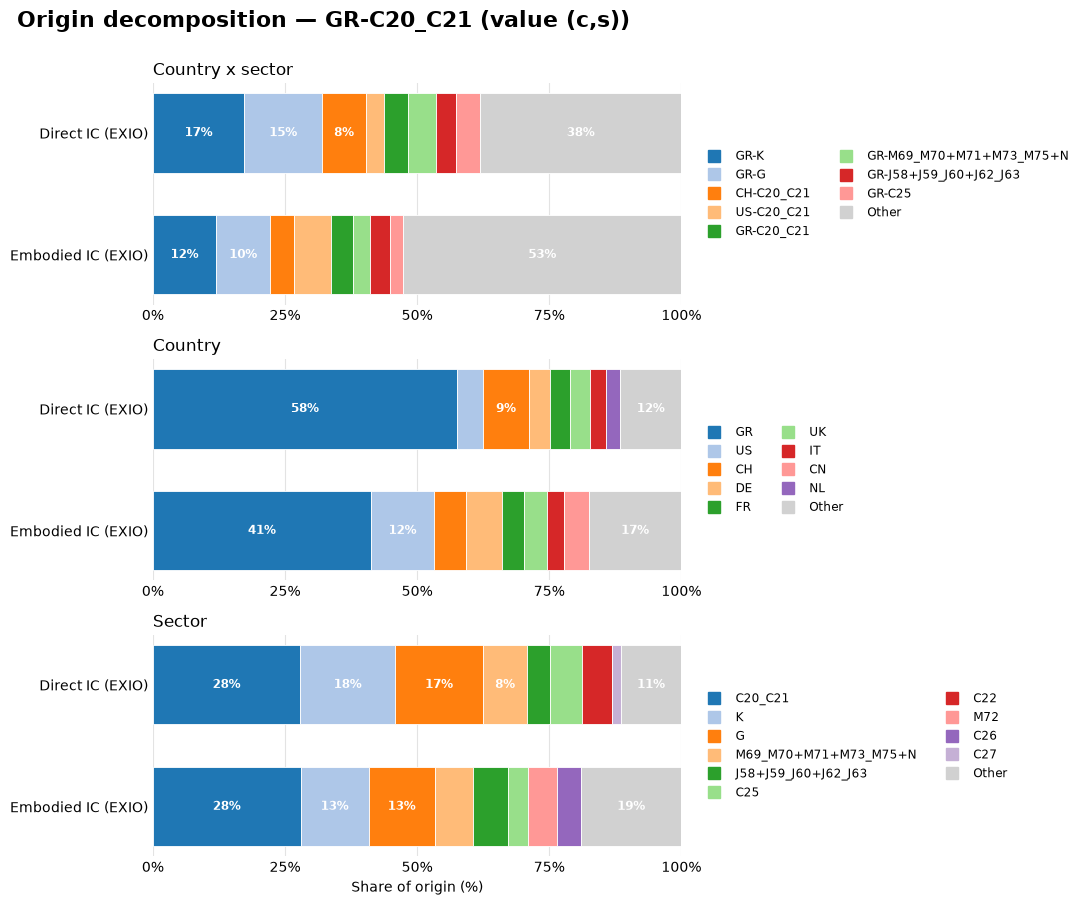

In [72]:
# Example 1: where does the R&D received by Greece in chemicals (C20_C21) come from, compared across bases / channels.
# All sources use DEFAULT_RUN (the run of project_settings, unless DEFAULT_RUN is edited above).
_BASE_METRICS = [
    ("EXIOBASE", "rd_dir_CI", "Direct IC (EXIO)"),
    ("FIGARO", "rd_dir_CI", "Direct IC (FIG)"),
    ("OECD_ICIO", "rd_dir_CI", "Direct IC (OECD)"),
    ("GTAP", "rd_dir_CI", "Direct IC (GTAP)"),
    ("EXIOBASE", "rd_embod_CI", "Embodied IC (EXIO)"),
    ("FIGARO", "rd_embod_CI", "Embodied IC (FIG)"),
    ("OECD_ICIO", "rd_embod_CI", "Embodied IC (OECD)"),
    ("GTAP", "rd_embod_CI", "Embodied IC (GTAP)"),
    ("CFC", "rd_dir_CFC", "Direct Capital"),
    ("CFC", "rd_embod_CFC", "Embodied Capital"),
    ("Patents_Citation", "rd_dir_cit", "Patent citations"),
    ("FDI", "rd_dir_fdips", "FDI"),
]
SOURCES_EXAMPLE = [(b, m, EXAMPLE_YEAR) for b, m, _ in _BASE_METRICS]
LABELS_EXAMPLE = {(b, m, EXAMPLE_YEAR): label for b, m, label in _BASE_METRICS}

LEVEL_LABELS = {
    "country_sector": "country x sector",
    "country": "country",
    "sector": "sector",
}

plot_origin_decomposition_panels(
    SOURCES_EXAMPLE, region="GR", item="C20_C21", top_n=8,
    labels=LABELS_EXAMPLE,
    other_label="Other",
    level_labels=LEVEL_LABELS,
    xlabel_text="Share of origin (%)",
    no_data_text="(no data)",
)

SKIP ('EXIOBASE', 'rd_dir_CI', 2020, 'SRDV (c,s,t)/TJ11'): no file in the catalog (run 'SRDV (c,s,t)/TJ11')
SKIP ('EXIOBASE', 'rd_dir_CI', 2020, 'SRDV (c,s,t)/TJ07'): no file in the catalog (run 'SRDV (c,s,t)/TJ07')


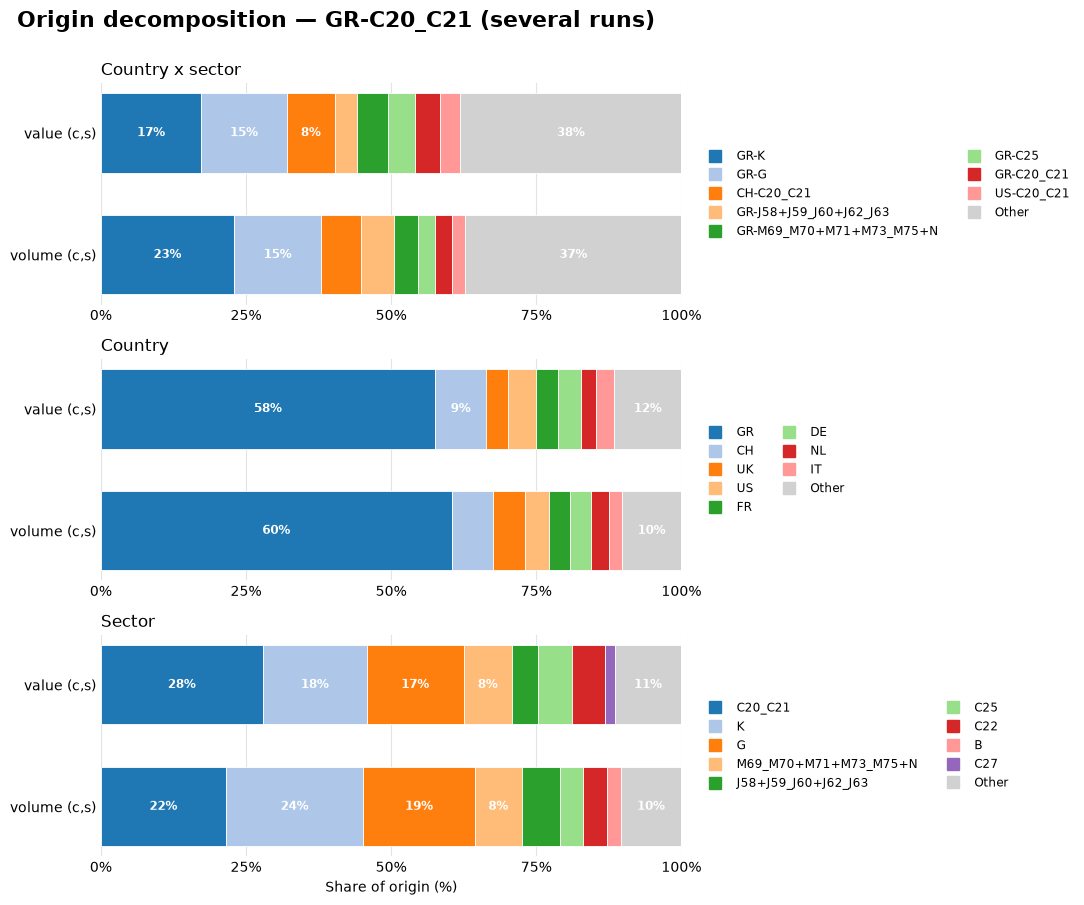

In [73]:
# Example 2: same base and metric, several runs = value vs volume, with / without technology.
# Each source carries its run as 4th element; runs that do not exist are skipped (see the catalog above).
RUNS_TO_COMPARE = [
    run_id("value", "(c,s)"),
    run_id("volume", "(c,s)"),
    run_id("value", "(c,s,t)", "TJ11"),
    run_id("value", "(c,s,t)", "TJ07"),
]
SOURCES_RUNS = [("EXIOBASE", "rd_dir_CI", EXAMPLE_YEAR, r) for r in RUNS_TO_COMPARE]
LABELS_RUNS = {src_: run_label(src_[3]) for src_ in SOURCES_RUNS}

plot_origin_decomposition_panels(
    SOURCES_RUNS, region="GR", item="C20_C21", top_n=8,
    labels=LABELS_RUNS,
    other_label="Other",
    level_labels=LEVEL_LABELS,
    xlabel_text="Share of origin (%)",
    no_data_text="(no data)",
    save_name="Origin_decomposition_GR-C20_C21_runs",
)
